In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score
from sklearn.model_selection import KFold


In [32]:
df=pd.read_csv('course_lead_scoring_2026.csv')
df.isnull().sum()
categorical=df.select_dtypes(include=['str']).columns.tolist()
numerical=df.select_dtypes(exclude=['str']).columns.tolist()
df[categorical]=df[categorical].fillna('NA')
df[numerical]=df[numerical].fillna(0.0)


In [33]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [34]:
# Question 1: ROC AUC feature importance
# ROC AUC could also be used to evaluate feature importance of numerical variables.

# Let's do that

# For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
# Use the training dataset for that
# If your AUC is < 0.5, invert this variable by putting "-" in front

# (e.g. -df_train['balance'])

# AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

# Which numerical variable (among the following 4) has the highest AUC?

# lead_score
# number_of_courses_viewed
# interaction_count
# annual_income

variables= [
    'lead_score',
    'number_of_courses_viewed',
    'interaction_count',
    'annual_income'
] #YA LAS HABÍA CALCULADO BIEN ANTES PERO POR SI ACASO LAS HAGO OTRA VEZ 

for col in variables:
    auc = roc_auc_score(df_train['converted'], df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[col])

    print(col, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [35]:
# Question 2: Training the model
# Apply one-hot-encoding using DictVectorizer and train the logistic regression with these parameters:

# LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
# What's the AUC of this model on the validation dataset? (round to 3 digits)

# 0.532
# 0.632
# 0.732
# 0.832

dv = DictVectorizer(sparse=False)

train_dicts = df_train.drop(columns=['converted']).to_dict(orient='records')
val_dicts = df_val.drop(columns=['converted']).to_dict(orient='records')

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train['converted']
y_val = df_val['converted']

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


Threshold: 0.63
Precision: 0.733
Recall: 0.725


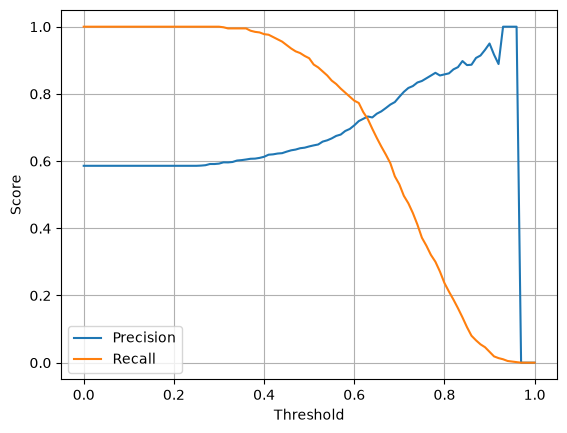

In [36]:
# Question 3: Precision and Recall
# Now let's compute precision and recall for our model.

# Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
# For each threshold, compute precision and recall
# Plot them
# At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

# 0.43
# 0.63
# 0.73
# 0.83

# Probabilidades de la clase positiva
y_pred = model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.0, 1.01, 0.01)
precisions = []
recalls = []

for t in thresholds:
    y_pred_bin = (y_pred >= t).astype(int)

    precision = precision_score(y_val, y_pred_bin, zero_division=0) #Si tuviera que dividir por 0 entonces devovlería 0 
    recall = recall_score(y_val, y_pred_bin, zero_division=0)

    precisions.append(precision)
    recalls.append(recall)

# Excluir thresholds donde ambas métricas son cero
differences = []

for p, r in zip(precisions, recalls): #Recorre juntos los valores 
    if p == 0 and r == 0:
        differences.append(np.inf)
    else:
        differences.append(abs(p - r))

best_idx = np.argmin(differences)
print("Threshold:", round(thresholds[best_idx], 2))
print("Precision:", round(precisions[best_idx], 3))
print("Recall:", round(recalls[best_idx], 3))

# Plot
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [37]:
# Question 4: F1 score
# Precision and recall are conflicting - when one grows, the other goes down. That's why they are often combined into the F1 score - a metrics that takes into account both

#VER FÓRMULA F1 SCORE 

# Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

# At which threshold F1 is maximal?

# 0.21
# 0.41
# 0.61
# 0.81

thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    y_pred_bin = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_bin, zero_division=0)
    r = recall_score(y_val, y_pred_bin, zero_division=0)

    if p + r == 0:
        f1 = 0
    else:
        f1 = 2 * p * r / (p + r)

    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)

print("Best threshold:", round(thresholds[best_idx], 2))
print("Best F1:", round(f1_scores[best_idx], 3))

Best threshold: 0.41
Best F1: 0.758


In [40]:
# Question 5: 5-Fold CV
# Use the KFold class from Scikit-Learn to evaluate our model on 5 different folds:

# KFold(n_splits=5, shuffle=True, random_state=1)
# Iterate over different folds of df_full_train
# Split the data into train and validation
# Train the model on train with these parameters: LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
# Use AUC to evaluate the model on validation
# How large is standard deviation of the scores across different folds?

# 0.001
# 0.007
# 0.013
# 0.060

kf = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kf.split(df_full_train):

    df_fold_train = df_full_train.iloc[train_idx]
    df_fold_val = df_full_train.iloc[val_idx]

    # Convert features to dictionaries
    train_dicts = df_fold_train.drop(
        columns=['converted']
    ).to_dict(orient='records')

    val_dicts = df_fold_val.drop(
        columns=['converted']
    ).to_dict(orient='records')

    # One-hot encoding
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    y_train = df_fold_train['converted']
    y_val = df_fold_val['converted']

    # Train model
    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000
    )
    model.fit(X_train, y_train)

    # Calculate AUC
    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)
    print(f"AUC: {auc:.3f}")

print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))

AUC: 0.731
AUC: 0.730
AUC: 0.736
AUC: 0.741
AUC: 0.721
Mean AUC: 0.732
Standard deviation: 0.007


In [ ]:
# Question 6: Hyperparameter Tuning
# Now let's use 5-Fold cross-validation to find the best parameter C

# Iterate over the following C values: [0.000001, 0.001, 1]
# Initialize KFold with the same parameters as previously
# Use these parameters for the model: LogisticRegression(solver='liblinear', C=C, max_iter=1000)
# Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).
# Which C leads to the best mean ROC AUC?

# 0.000001
# 0.001
# 1
# If you have ties, select the score with the lowest std. If you still have ties, select the smallest C.

C_values = [0.000001, 0.001, 1]

kf = KFold(n_splits=5, shuffle=True, random_state=1)

results = []

for C in C_values:
    scores = []

    for train_idx, val_idx in kf.split(df_full_train):
        df_fold_train = df_full_train.iloc[train_idx]
        df_fold_val = df_full_train.iloc[val_idx]

        train_dicts = df_fold_train.drop(
            columns=['converted']
        ).to_dict(orient='records')

        val_dicts = df_fold_val.drop(
            columns=['converted']
        ).to_dict(orient='records')

        dv = DictVectorizer(sparse=False)
        X_train = dv.fit_transform(train_dicts)
        X_val = dv.transform(val_dicts)

        y_train = df_fold_train['converted']
        y_val = df_fold_val['converted']

        model = LogisticRegression(
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        model.fit(X_train, y_train)

        y_pred = model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results.append({
        'C': C,
        'mean_auc': mean_auc,
        'std_auc': std_auc
    })

# results_df = pd.DataFrame(results)
# print(results_df.round(3).to_string(index=False)) #ESTÁ BIEN PERO REDONDEA EL VALOR DE C TAMBIÉN ASÍ QUE PODRÍA LLEVAR A CONFUSIÓN 

for result in results:
    print(
        f"C={result['C']}, "
        f"mean={result['mean_auc']:.3f}, "
        f"std={result['std_auc']:.3f}"
    ) 

C=1e-06, mean=0.617, std=0.019
C=0.001, mean=0.749, std=0.010
C=1, mean=0.732, std=0.007
